# Satellite collision risk evaluator — development and training

Use this notebook to develop and evaluate the model. Training data are local to this folder;
test telemetry is read from `../prediction/test_data.csv`. Experimental models, encoders,
evaluation reports, and dashboard exports are written to this folder's `artifacts/`.

From the repository root, prepare the separate development environment:

```bash
python3 -m venv development/.venv
development/.venv/bin/python -m pip install -r development/requirements-dev.lock.txt
```

Open JupyterLab with the configured interpreter and local OpenMP runtime:

```bash
development/.venv/bin/python development/execute_notebook.py --lab
```

Or execute and save all cells headlessly:

```bash
development/.venv/bin/python development/execute_notebook.py
```

Training leaves the deployed model in `../prediction/artifacts/` unchanged. See this folder's
README for copying a reviewed model and encoder into the prediction workflow.


## Prediction contract and distance units

- Target: the **same row's** `risk` value; it is already logarithmic.
- Inputs: exactly the 12 requested source features, including `event_id`.
- Test protection: drop `risk`, `max_risk_estimate`, and `max_risk_scaling` before inference;
  no test targets are used for fitting, early stopping, scoring, or model selection.
- The supplied files match the [ESA Kelvins dataset](https://kelvins.esa.int/collision-avoidance-challenge/data/),
  whose documentation specifies `miss_distance` in **metres**, relative speed in m/s, and
  `time_to_tca` in days. Classification converts metres to kilometres.
- Export every telemetry row in input order. A second CSV selects the latest available
  telemetry row per event, using the minimum `time_to_tca`.

**Target horizon:** the original ESA competition predicts an event's final risk from earlier
messages. This implementation follows the requested row-level target. Removing test target
columns prevents target leakage; it does not turn a row-level regressor into a final-TCA
forecaster. No future rows are aggregated into the feature set.

The tier rules below are the policy specified in the prompt; this notebook does not establish
that the complete three-tier policy is a universal NASA/ESA standard.


In [1]:
from pathlib import Path
import json
import os
import sys
import subprocess

PROJECT_ROOT = Path.cwd().resolve()
if (PROJECT_ROOT / "development" / "collision_risk.py").exists():
    PROJECT_ROOT = PROJECT_ROOT / "development"
if not (PROJECT_ROOT / "collision_risk.py").exists():
    raise FileNotFoundError("Open this notebook from the repository root or development/.")
sys.path.insert(0, str(PROJECT_ROOT))
# Keep optional plotting caches within the writable project directory.
os.environ.setdefault("MPLCONFIGDIR", str(PROJECT_ROOT / ".cache" / "matplotlib"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from collision_risk import (
    FEATURES, FORBIDDEN_TEST_COLUMNS, TIERS, SAFE, ELEVATED, CRITICAL,
    TrainingConfig, FeatureEncoder, classify_risk, require_columns,
    load_train_data, load_test_data, evaluate_model, fit_final_model,
    dashboard_predictions, latest_event_predictions, save_artifacts,
)
import xgboost

pd.set_option("display.max_columns", 20)
print({"python": sys.version.split()[0], "pandas": pd.__version__,
       "numpy": np.__version__, "xgboost": xgboost.__version__})


{'python': '3.13.7', 'pandas': '3.1.0', 'numpy': '2.5.4', 'xgboost': '3.4.1'}


## Configuration

The CPU histogram regressor keeps the same feature allowlist and risk thresholds.
Frequency-adaptive weights make rare high-risk errors expensive. Validation events select
weights and boosting rounds, prioritizing the worst probability-band recall. Candidates must
also beat the fit-mean constant's validation RMSE. The holdout and test CSV never select costs.


In [2]:
TRAIN_PATH = PROJECT_ROOT / "train_data.csv"
TEST_PATH = PROJECT_ROOT.parent / "prediction" / "test_data.csv"
OUTPUT_DIR = PROJECT_ROOT / "artifacts"

config = TrainingConfig(
    random_state=42,
    max_estimators=1600,
    early_stopping_rounds=80,
    max_depth=7,
    learning_rate=0.04,
    distance_unit="m",
)
print(config)
print("Allowed source features:", list(FEATURES))


TrainingConfig(random_state=42, holdout_fraction=0.2, validation_fraction=0.2, max_estimators=1600, early_stopping_rounds=80, learning_rate=0.04, max_depth=7, n_jobs=8, distance_unit='m', class_balance_power=1.0, elevated_weight=20.0, critical_weight=320.0)
Allowed source features: ['event_id', 'time_to_tca', 'miss_distance', 'relative_speed', 'relative_position_r', 'relative_position_t', 'relative_position_n', 'c_object_type', 'c_sigma_r', 't_sigma_r', 'F10', 'AP']


## Load training data and explicitly sanitize test data

Only approved inputs and the training target are loaded from the 103-column training CSV.
The test cell below visibly drops all three forbidden fields. The script's `load_test_data()`
performs the same sanitization and is covered by tests. Existing numeric event IDs are
independently numbered across files: do not join train and test on `event_id`.


In [3]:
train_data = load_train_data(TRAIN_PATH)

# Read relevant columns, then EXPLICITLY REMOVE all forbidden test fields.
test_data = pd.read_csv(
    TEST_PATH,
    usecols=lambda name: name in (*FEATURES, *FORBIDDEN_TEST_COLUMNS),
)
test_data = test_data.drop(columns=list(FORBIDDEN_TEST_COLUMNS), errors="ignore")
require_columns(test_data, FEATURES)
test_data = test_data.loc[:, list(FEATURES)].copy()

assert not set(FORBIDDEN_TEST_COLUMNS).intersection(test_data.columns)
assert list(test_data.columns) == list(FEATURES)
assert list(train_data.columns) == [*FEATURES, "risk"]
assert train_data["risk"].le(0).all(), "risk must already be log10(Pc)"
print(f"Training rows: {len(train_data):,}; test rows: {len(test_data):,}")
display(pd.DataFrame({
    "rows": [len(train_data), len(test_data)],
    "events": [train_data.event_id.nunique(), test_data.event_id.nunique()],
}, index=["train", "sanitized_test"]))
display(test_data.head())


Training rows: 162,634; test rows: 24,484


,rows,events
train,162634,13154
sanitized_test,24484,2167


,event_id,time_to_tca,miss_distance,relative_speed,relative_position_r,relative_position_t,relative_position_n,c_object_type,c_sigma_r,t_sigma_r,F10,AP
0,0,6.842095,31816.0,7929.0,-365.5,26967.0,16880.6,UNKNOWN,212.775210,7.414544,76.0,11.0
1,0,6.571818,31095.0,7929.0,-361.8,26356.6,16497.2,UNKNOWN,212.758643,7.413035,75.0,9.0
2,0,6.112986,32202.0,7929.0,-370.7,27294.4,17085.1,UNKNOWN,212.784398,7.834560,75.0,9.0
3,0,5.921955,32878.0,7929.0,-376.3,27867.5,17443.8,UNKNOWN,212.793280,7.353785,75.0,9.0
4,0,2.228761,32792.0,7929.0,-375.6,27793.8,17399.4,UNKNOWN,212.798144,5.833502,71.0,4.0


,train_missing,test_missing
event_id,0,0
time_to_tca,0,0
miss_distance,0,0
relative_speed,0,0
relative_position_r,0,0
relative_position_t,0,0
relative_position_n,0,0
c_object_type,0,0
c_sigma_r,11,6
t_sigma_r,0,0


,risk
count,162634.000000
mean,-19.340603
std,10.011641
min,-30.000000
1%,-30.000000
50%,-17.870632
90%,-6.576148
99%,-4.480784
max,-1.442854


Train Pc >= 1e-4: 716
Train targets at the -30 floor: 67240
Test time_to_tca range (days): 2.000213078703704 6.993168715277778


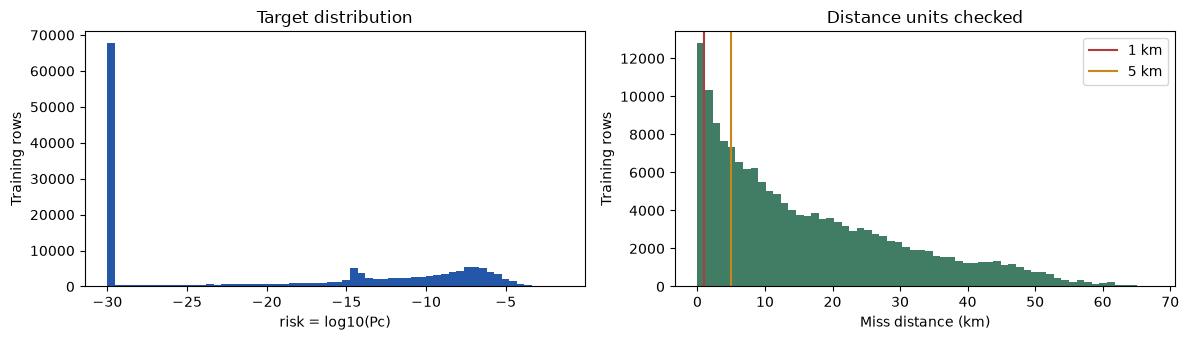

In [4]:
missingness = pd.DataFrame({
    "train_missing": train_data.loc[:, list(FEATURES)].isna().sum(),
    "test_missing": test_data.isna().sum(),
})
display(missingness)
display(train_data["risk"].describe(percentiles=[0.01, 0.5, 0.9, 0.99]).to_frame())
print("Train Pc >= 1e-4:", int(train_data["risk"].ge(-4).sum()))
print("Train targets at the -30 floor:", int(train_data["risk"].eq(-30).sum()))
print("Test time_to_tca range (days):", test_data.time_to_tca.min(), test_data.time_to_tca.max())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(train_data["risk"], bins=60, color="#2457a7")
axes[0].set(xlabel="risk = log10(Pc)", ylabel="Training rows", title="Target distribution")
axes[1].hist(train_data["miss_distance"] / 1000, bins=60, color="#417d65")
axes[1].axvline(1, color="#b33a3a", label="1 km")
axes[1].axvline(5, color="#c88718", label="5 km")
axes[1].set(xlabel="Miss distance (km)", ylabel="Training rows", title="Distance units checked")
axes[1].legend()
fig.tight_layout()
plt.show()


## Deterministic operational tiers

Evaluate the highest-priority matching rule first. Critical overrides Elevated wherever the
conditions overlap. Exactly 1.0 and 5.0 km belong to the Elevated distance band.

| Priority | Tier | Rule |
|---|---|---|
| 1 | Critical (Maneuver Required) | predicted risk $\ge -4$ **or** distance $<1$ km |
| 2 | Elevated risk | $-6\le$ predicted risk $<-4$ **or** $1\le$ distance $\le5$ km |
| 3 | Safe | predicted risk $<-6$ **and** distance $>5$ km |

The function compares log-risk directly: `risk >= -4` is equivalent to `Pc >= 1e-4`,
and avoids numerical underflow in very small probabilities. `Pc = 10**predicted_risk` is
available whenever a probability is needed for display. Nonfinite risks, missing distances,
and negative distances raise errors rather than producing a misleading tier.


In [5]:
boundary_examples = pd.DataFrame({
    "predicted_risk": [-7, -6, -4, -7, -7, -7, -5],
    "miss_distance_km": [6, 6, 6, 5, 1, 0.999, 0.5],
    "expected": [SAFE, ELEVATED, CRITICAL, ELEVATED, ELEVATED, CRITICAL, CRITICAL],
})
boundary_examples["risk_tier"] = classify_risk(
    boundary_examples.predicted_risk,
    boundary_examples.miss_distance_km,
    distance_unit="km",
)
assert boundary_examples.risk_tier.equals(boundary_examples.expected)
display(boundary_examples)

# Execute the reusable behavioral tests before the expensive training cells.
checks = subprocess.run(
    [sys.executable, "-m", "pytest", "-q", "tests"],
    cwd=PROJECT_ROOT, capture_output=True, text=True,
)
print(checks.stdout)
if checks.returncode:
    print(checks.stderr)
checks.check_returncode()


,predicted_risk,miss_distance_km,expected,risk_tier
0,-7,6.000,Safe,Safe
1,-6,6.000,Elevated risk,Elevated risk
2,-4,6.000,Critical (Maneuver Required),Critical (Maneuver Required)
3,-7,5.000,Elevated risk,Elevated risk
4,-7,1.000,Elevated risk,Elevated risk
5,-7,0.999,Critical (Maneuver Required),Critical (Maneuver Required)
6,-5,0.500,Critical (Maneuver Required),Critical (Maneuver Required)


........................................................................ [ 86%]
...........                                                              [100%]
83 passed in 4.18s



## Select class costs, then assess unseen events

`GroupShuffleSplit` assigns approximately 64% / 16% / 20% of events to fit / validation /
holdout. Every report for an event stays together. On fitting rows only, costs are
`(n / (k * class_count)) ** power * class_multiplier`, normalized to mean one.
We compare the unweighted RMSE baseline with a bounded 3×3 cost grid. Weighted candidates
use `balanced_band_error` for early stopping: minimize
`1 - (minimum band recall + 0.05 * macro recall) / 1.05`. Probability bands use -6/-4 without
distance overrides. This discourages an all-Critical shortcut. The same validation RMSE
guard is applied when selecting candidates. After costs/rounds are frozen, the holdout is assessed.

Higher sensitivity can increase false alerts and regression error. Inspect all metrics;
roughly equal per-class recall is an objective, not a guarantee or probability calibration.


In [6]:
evaluation = evaluate_model(train_data, config)
config = evaluation["selected_config"]
metrics = evaluation["metrics"]
best_rounds = metrics["selected_boosting_rounds"]

partitions = evaluation["partitions"]
event_sets = {name: set(train_data.iloc[idx].event_id) for name, idx in partitions.items()}
assert event_sets["fit"].isdisjoint(event_sets["validation"])
assert event_sets["fit"].isdisjoint(event_sets["holdout"])
assert event_sets["validation"].isdisjoint(event_sets["holdout"])
display(pd.DataFrame(metrics["partitions"]).T)
display(pd.DataFrame({
    "XGBoost": metrics["holdout_xgboost"],
    "Mean baseline": metrics["holdout_mean_baseline"],
}).T)
print("Selected boosting rounds:", best_rounds)
if best_rounds == config.max_estimators:
    print("Training reached the configured boosting budget; early stopping did not shorten it.")
print("Early-CDM holdout:", metrics.get("holdout_time_to_tca_gt_2_days"))

trials = metrics["weight_selection"]["trials"]
display(pd.DataFrame([{
    "power": t["class_balance_power"], "elevated_weight": t["elevated_weight"],
    "critical_weight": t["critical_weight"], "rounds": t["rounds"],
    "validation_min_recall": t["validation_probability_bands"]["worst_recall"],
    "validation_macro_recall": t["validation_probability_bands"]["macro_recall"],
    "validation_rmse": t["validation_rmse_log10_pc"], "eligible": t["eligible"],
} for t in trials]))
print("Selected training costs:", metrics["weight_selection"]["selected"]["fit_class_costs"])


,rows,events
fit,104230,8418
validation,26366,2105
holdout,32038,2631


,rmse_log10_pc,mae_log10_pc,r2
XGBoost,9.575038,6.919472,0.084656
Mean baseline,10.008402,9.485998,-0.000076


Selected boosting rounds: 125
Early-CDM holdout: {'rows': 21944, 'rmse_log10_pc': 9.221693946135202, 'mae_log10_pc': 6.502195225227913, 'r2': 0.06829146155199128}


,power,elevated_weight,critical_weight,rounds,validation_min_recall,validation_macro_recall,validation_rmse,eligible
0,0.0,1.0,1.0,356,0.084967,0.409699,5.843589,True
1,1.0,20.0,320.0,125,0.665666,0.728008,9.809212,True
2,1.0,5.0,5.0,82,0.261438,0.606545,7.312391,True
3,1.0,5.0,20.0,40,0.614379,0.701788,9.313268,True
4,1.0,5.0,80.0,30,0.542017,0.752404,11.534694,False
5,1.0,20.0,20.0,70,0.235294,0.622358,8.806118,True
6,1.0,20.0,80.0,34,0.666667,0.721221,11.725705,False
7,1.0,80.0,80.0,44,0.202614,0.590532,11.918121,False
8,1.0,80.0,320.0,36,0.562065,0.658365,13.909460,False
9,1.0,80.0,1280.0,102,0.647059,0.710552,12.972300,False


Selected training costs: [0.003122259354698518, 1.0347319703687232, 230.14386751768157]


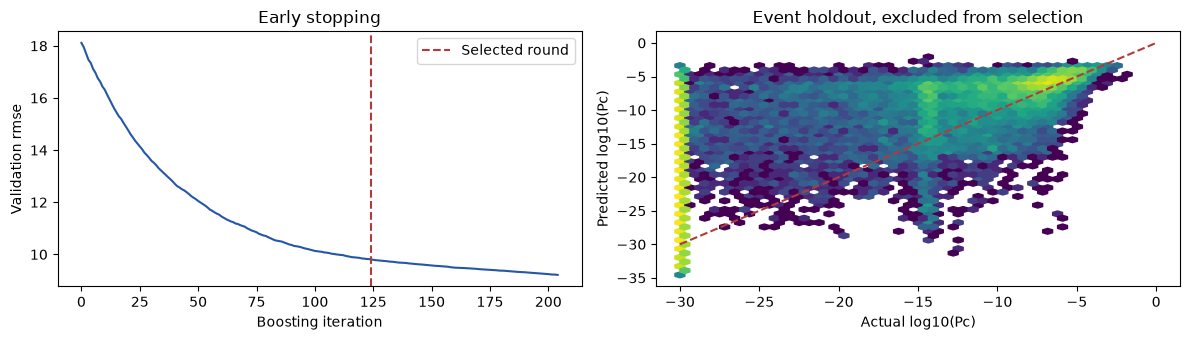

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
metric_name, validation_curve = next(iter(evaluation["model"].evals_result()["validation_0"].items()))
axes[0].plot(validation_curve, color="#2457a7")
axes[0].axvline(best_rounds - 1, color="#b33a3a", linestyle="--", label="Selected round")
axes[0].set(xlabel="Boosting iteration", ylabel=f"Validation {metric_name}", title="Early stopping")
axes[0].legend()
axes[1].hexbin(evaluation["holdout_actual"], evaluation["holdout_prediction"],
               gridsize=45, mincnt=1, bins="log", cmap="viridis")
axes[1].plot([-30, 0], [-30, 0], color="#b33a3a", linestyle="--")
axes[1].set(xlabel="Actual log10(Pc)", ylabel="Predicted log10(Pc)", title="Event holdout, excluded from selection")
fig.tight_layout()
plt.show()


## Tier and probability-threshold diagnostics

The reference tier combines the observed training target with that row's distance.
A distance below 1 km creates a Critical tier even if the probability prediction is poor.
Therefore probability-only precision and recall at both 1e-6 and 1e-4 are reported separately.
Inspect these metrics before treating tier accuracy as evidence of probability prediction quality.
The large -30 target floor and rare high-probability cases are also visible above.


In [8]:
display(pd.DataFrame(metrics["tier_report"]).T)
display(pd.DataFrame(metrics["tier_confusion_matrix"], index=pd.Index(TIERS, name="actual"),
                     columns=pd.Index(TIERS, name="predicted")))
display(pd.DataFrame({
    "Pc >= 1e-6": metrics["probability_only_risk_ge_-6"],
    "Pc >= 1e-4": metrics["probability_only_risk_ge_-4"],
}).T)

# Compare probability-band recall independently of the distance override.
weighted = metrics["holdout_probability_bands"]["report"]
baseline = metrics["holdout_unweighted_xgboost"]["probability_bands"]["report"]
display(pd.DataFrame({
    "Unweighted recall": {tier: baseline[tier]["recall"] for tier in TIERS},
    "Weighted recall": {tier: weighted[tier]["recall"] for tier in TIERS},
    "Weighted precision": {tier: weighted[tier]["precision"] for tier in TIERS},
    "Reference reports": {tier: weighted[tier]["support"] for tier in TIERS},
}))
print("Probability-band confusion matrix:")
display(pd.DataFrame(metrics["holdout_probability_bands"]["confusion_matrix"],
                     index=pd.Index(TIERS, name="actual"), columns=TIERS))


,precision,recall,f1-score,support
Safe,0.987115,0.913208,0.948724,22986.000000
Elevated risk,0.751482,0.922797,0.828375,6593.000000
Critical (Maneuver Required),0.910721,0.991460,0.949377,2459.000000
accuracy,0.921187,0.921187,0.921187,0.921187
macro avg,0.883106,0.942488,0.908825,32038.000000
weighted avg,0.932761,0.921187,0.924008,32038.000000


predicted,Safe,Elevated risk,Critical (Maneuver Required)
actual,,,
Safe,20991,1992,3
Elevated risk,273,6084,236
Critical (Maneuver Required),1,20,2438


,precision,recall,f1,actual_positive_rows,predicted_positive_rows
Pc >= 1e-6,0.288144,0.817331,0.426078,2031.0,5761.0
Pc >= 1e-4,0.137874,0.601449,0.224324,138.0,602.0


,Unweighted recall,Weighted recall,Weighted precision,Reference reports
Safe,0.993035,0.863332,0.985881,30007.0
Elevated risk,0.150555,0.648177,0.237837,1893.0
Critical (Maneuver Required),0.036232,0.601449,0.137874,138.0


Probability-band confusion matrix:


,Safe,Elevated risk,Critical (Maneuver Required)
actual,,,
Safe,25906,3880,221
Elevated risk,368,1227,298
Critical (Maneuver Required),3,52,83


## Refit the selected weighted regressor and predict sanitized inputs

Use the selected configuration and fixed tree count. Recompute class-frequency weights on
all training rows only. The saved native XGBoost model needs no weighting at inference.
`predicted_risk` stays in log space and is capped at zero. Cost-sensitive outputs trade numerical
fidelity for sensitivity and must not be described as calibrated collision probabilities.


In [9]:
model, encoder = fit_final_model(train_data, config, best_rounds)

assert not set(FORBIDDEN_TEST_COLUMNS).intersection(test_data.columns)
assert list(test_data.columns) == list(FEATURES)
dashboard_data = dashboard_predictions(model, encoder, test_data,
                                       distance_unit=config.distance_unit)
latest_event_data = latest_event_predictions(dashboard_data, test_data)

assert list(dashboard_data.columns) == ["event_id", "predicted_risk", "risk_tier"]
assert len(dashboard_data) == len(test_data)
assert dashboard_data.event_id.tolist() == test_data.event_id.tolist()
assert np.isfinite(dashboard_data.predicted_risk).all()
assert dashboard_data.predicted_risk.le(0).all()
assert set(dashboard_data.risk_tier).issubset(TIERS)
assert latest_event_data.event_id.is_unique
assert len(latest_event_data) == test_data.event_id.nunique()
display(dashboard_data.head(10))
display(dashboard_data.risk_tier.value_counts().rename("telemetry_rows").to_frame())
print(f"Per-row export: {len(dashboard_data):,}; latest-event export: {len(latest_event_data):,}")


,event_id,predicted_risk,risk_tier
0,0,-5.582961,Elevated risk
1,0,-5.582961,Elevated risk
2,0,-5.579866,Elevated risk
3,0,-6.575769,Safe
4,0,-8.865563,Safe
5,1,-9.557096,Critical (Maneuver Required)
6,1,-9.296267,Critical (Maneuver Required)
7,2,-5.385740,Elevated risk
8,2,-5.412853,Elevated risk
9,2,-5.498551,Elevated risk


,telemetry_rows
risk_tier,
Safe,13754
Elevated risk,8245
Critical (Maneuver Required),2485


Per-row export: 24,484; latest-event export: 2,167


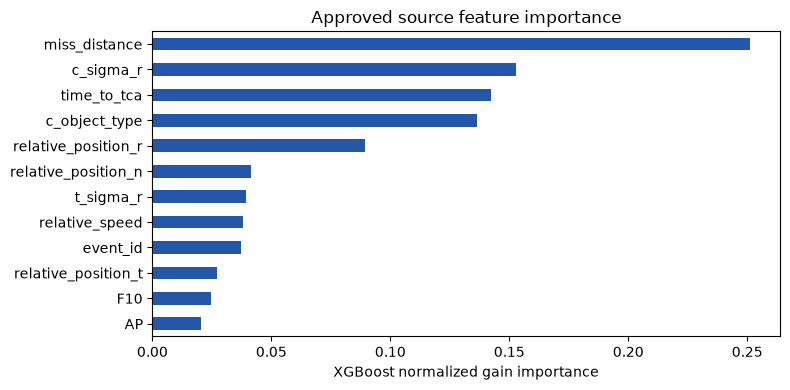

In [10]:
importance = pd.Series(model.feature_importances_, index=encoder.output_columns_)
# Aggregate category indicators back to their one approved source feature.
source_importance = importance.groupby(
    lambda name: "c_object_type" if name.startswith("c_object_type_") else name
).sum().reindex(FEATURES).sort_values()
ax = source_importance.plot.barh(figsize=(8, 4), color="#2457a7")
ax.set(xlabel="XGBoost normalized gain importance", title="Approved source feature importance")
plt.tight_layout()
plt.show()


## Export dashboard datasets and a reusable model

`dashboard_predictions.csv` contains exactly the requested three fields, one row per test CDM.
`dashboard_latest_events.csv` contains the same fields, one row per event selected from its
latest available CDM. It is an optional current-event UI view, not a forecast of final-event risk.

The encoder metadata and model are saved separately so future sanitized telemetry can be
predicted without refitting. Evaluation metadata records configuration, units, feature contract,
holdout performance, and chosen boosting rounds.


In [11]:
save_artifacts(OUTPUT_DIR, model, encoder, dashboard_data, latest_event_data, metrics, config)

# Verify the saved model+encoder reproduce the exported predictions.
restored_model = xgboost.XGBRegressor()
restored_model.load_model(OUTPUT_DIR / "collision_risk_model.ubj")
restored_encoder = FeatureEncoder.load(OUTPUT_DIR / "feature_encoder.json")
restored_predictions = dashboard_predictions(restored_model, restored_encoder, test_data,
                                               distance_unit=config.distance_unit)
pd.testing.assert_frame_equal(dashboard_data, restored_predictions)

csv_check = pd.read_csv(OUTPUT_DIR / "dashboard_predictions.csv")
pd.testing.assert_frame_equal(csv_check, dashboard_data, check_exact=False, rtol=1e-12, atol=1e-12)
print("Saved artifacts verified:")
for artifact in sorted(OUTPUT_DIR.iterdir()):
    if artifact.is_file():
        print(f"  {artifact.name}: {artifact.stat().st_size:,} bytes")
display(latest_event_data.head(10))


Saved artifacts verified:
  collision_risk_model.ubj: 617,795 bytes
  dashboard_latest_events.csv: 71,879 bytes
  dashboard_predictions.csv: 838,016 bytes
  evaluation.json: 29,772 bytes
  feature_encoder.json: 774 bytes
  loss_experiment.json: 3,688 bytes
  loss_experiment.py: 2,176 bytes
  loss_experiment2.json: 3,699 bytes
  loss_experiment2.py: 2,272 bytes
  prediction_benchmark.json: 3,757 bytes
  weight_experiment.json: 3,042 bytes
  weight_experiment.py: 1,376 bytes
  weight_experiment2.json: 4,922 bytes
  weight_experiment2.py: 1,461 bytes
  weight_experiment3.json: 4,926 bytes
  weight_experiment3.py: 1,701 bytes


,event_id,predicted_risk,risk_tier
0,0,-8.865563,Safe
1,1,-9.296267,Critical (Maneuver Required)
2,2,-26.882002,Safe
3,3,-14.085131,Safe
4,4,-25.789616,Safe
5,5,-16.532408,Safe
6,6,-6.779702,Safe
7,7,-26.872314,Safe
8,8,-6.175089,Safe
9,9,-27.638302,Safe


## Next development experiments

Use the early-stopping partition or additional grouped folds for experiments; reserve a fresh
holdout if repeatedly comparing models against the current holdout. Useful follow-ups include
an identifier ablation, additional grouped-fold sensitivity checks, and a separate
final-TCA forecasting task with explicitly aligned per-event targets and observation cutoffs.

The deterministic thresholds are fully specified; the estimated `Pc` still depends on regression
quality. Regressing log10(Pc) does not guarantee calibrated probability estimates after exponentiation.

References: [ESA data schema and units](https://kelvins.esa.int/collision-avoidance-challenge/data/),
[XGBoost histogram training and early stopping](https://xgboost.readthedocs.io/en/stable/python/sklearn_estimator.html).

The supplied labelled test CSV was previously inspected for baseline benchmarking. It is
not a fresh blind test. The cost search never reads its labels, and this run must not be
retuned after inspecting the holdout/test results. Use fresh event data for later tuning.
